<a href="https://colab.research.google.com/github/LuckySevenn/DAFT-BrainLat-AD-Classification/blob/main/notebooks/ftt_optimizadores_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FT-Transformer (CN vs AD) — comparación de optimizadores: Adam y SGD (momentum 0.9)

Mismo protocolo que `run_ftt.py`:
- mismos sujetos y particiones (columna `split` del master),
- grilla de learning rates × weight decays × batch sizes, ahora también por **optimizador**,
- batch con `drop_last`, 30 épocas, calendario de lr ×1 / ×0.1 / ×0.05 (60% y 90% de las épocas),
- pérdida `BCEWithLogits`, umbral 0.5, misma semilla,
- se conserva la época con mejor balanced accuracy en **validación** y con ese modelo se evalúa en validación y test.

Diferencias respecto a AdamW:
- **Adam**: `weight_decay` es regularización L2 sumada al gradiente (acoplada), no el decaimiento desacoplado de AdamW.
- **SGD**: momentum 0.9, `weight_decay` como L2.

**Antes de empezar:** Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU.

In [ ]:
!pip install -q rtdl_revisiting_models

In [ ]:
import copy, hashlib, io, itertools, json, random, shutil, time, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from rtdl_revisiting_models import FTTransformer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


## 1. Configuración

In [ ]:
EXPECTED_NAME = "master.csv"   # nombre esperado del CSV (solo para avisar si es otro)

ID_COL = "MRI_ID"
LABEL_COL = "DX"
SPLIT_COL = "split"
POSITIVE, NEGATIVE = "Dementia", "CN"   # en DX, AD está codificado como "Dementia"
CLASS_NAMES = ["CN", "AD"]              # 0 = CN, 1 = AD

# Columnas que NO son variables de entrada
EXCLUDE_COLS = [ID_COL, "country", "dx_brainlat", LABEL_COL, SPLIT_COL, "moca_total"]
CAT_FEATURES = ["sex"]                  # el resto son continuas

# Optimizadores a comparar. Agrega "AdamW" si quieres el original en la misma tabla.
OPTIMIZERS = ["Adam", "SGD"]
SGD_MOMENTUM = 0.9

# Learning rates por optimizador. Por defecto los mismos de run_ftt.py (comparables).
# SGD suele necesitar lr más altos que Adam; si con estos valores apenas aprende,
# prueba por ejemplo [1e-3, 3e-3, 1e-2, 3e-2, 1e-1].
LEARNING_RATES = {
    "AdamW": [1e-5, 3e-5, 1e-4, 3e-4, 1e-3],
    "Adam":  [1e-5, 3e-5, 1e-4, 3e-4, 1e-3],
    "SGD":   [1e-5, 3e-5, 1e-4, 3e-4, 1e-3],
}
DECAY_RATES = [0.0, 1e-4, 1e-2]
BATCH_SIZES = [8, 16, 32]
EPOCHS = 30
N_BLOCKS = 3                 # configuración por defecto del paper (d=192, 8 cabezas)
SEED = 20210129              # misma semilla que train.py de DAFT
DPI = 150
PROTOCOL_VERSION = "ftt-v3-daft-protocol-optim"

n_runs = sum(len(LEARNING_RATES[o]) for o in OPTIMIZERS) * len(DECAY_RATES) * len(BATCH_SIZES)
print("Corridas totales:", n_runs)

Corridas totales: 90


## 2. Seleccionar el CSV
Sube el `master.csv` (el mismo que se usó para crear los HDF5).

In [ ]:
from google.colab import files

BASE_DIR = Path("/content/ftt_optimizadores")
BASE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = BASE_DIR / "ftt_grid"
RESULTS_CSV = BASE_DIR / "ftt_optim_grid_results.csv"

uploaded = files.upload()   # abre el selector de archivos
if not uploaded:
    raise ValueError("No se seleccionó ningún archivo.")

fname = next(iter(uploaded))
if fname != EXPECTED_NAME:
    print("[AVISO] El archivo se llama '{}', se esperaba '{}'. Se usará de todas formas.".format(fname, EXPECTED_NAME))

raw_df = pd.read_csv(io.BytesIO(uploaded[fname]))
print("Cargado '{}': {} filas x {} columnas".format(fname, *raw_df.shape))

missing = [c for c in [ID_COL, LABEL_COL, SPLIT_COL] + CAT_FEATURES if c not in raw_df.columns]
if missing:
    raise ValueError("Faltan columnas en el CSV: {}".format(missing))

CSV_MD5 = hashlib.md5(uploaded[fname]).hexdigest()[:10]   # identifica el contenido del CSV para retomar
print("Resultados en:", BASE_DIR)

Saving master_brianlat.csv to master_brianlat.csv
[AVISO] El archivo se llama 'master_brianlat.csv', se esperaba 'master.csv'. Se usará de todas formas.
Cargado 'master_brianlat.csv': 343 filas x 24 columnas
Resultados en: /content/ftt_optimizadores


## 3. Datos

In [ ]:
def _norm_split(s):
    s = str(s).strip().lower()
    return {"val": "valid", "validation": "valid", "validacion": "valid", "validación": "valid"}.get(s, s)


def load_data():
    df = raw_df.copy()
    if df.empty:
        raise ValueError("El CSV no tiene sujetos (solo encabezados).")
    df[SPLIT_COL] = df[SPLIT_COL].map(_norm_split)
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin([POSITIVE, NEGATIVE])].reset_index(drop=True)

    cont_features = [c for c in df.columns if c not in EXCLUDE_COLS + CAT_FEATURES]
    for c in cont_features:
        converted = pd.to_numeric(df[c], errors="coerce")
        bad = df[c].notna() & converted.isna()
        if bad.any():
            print("  [AVISO] '{}': {} valores no numéricos tratados como faltantes. Ejemplos: {}".format(
                c, int(bad.sum()), sorted(df.loc[bad, c].astype(str).unique())[:5]))
        df[c] = converted

    train = df[df[SPLIT_COL] == "train"]
    if train.empty:
        raise ValueError("No hay sujetos de train.")

    # Continuas: mediana de train + z-score con estadísticas de train
    medians = train[cont_features].median()
    X = df[cont_features].astype("float32").fillna(medians)
    X_train = train[cont_features].astype("float32").fillna(medians)
    mean, std = X_train.mean(), X_train.std().replace(0, 1.0)
    X = (X - mean) / std

    # Categóricas: códigos 0..k-1 aprendidos en train; faltantes -> moda de train
    cat_codes, cardinalities = [], []
    for c in CAT_FEATURES:
        col = df[c].fillna(train[c].mode().iloc[0])
        cats = sorted(train[c].dropna().unique().tolist())
        unseen = set(col.unique()) - set(cats)
        if unseen:
            raise ValueError("La variable '{}' tiene valores que no aparecen en train: {}".format(c, unseen))
        cat_codes.append(col.map({v: i for i, v in enumerate(cats)}).astype("int64").values)
        cardinalities.append(len(cats))

    y = (df[LABEL_COL] == POSITIVE).astype("float32").values
    x_cat = np.stack(cat_codes, axis=1) if cat_codes else None

    data = {}
    for split in ["train", "valid", "test"]:
        idx = np.where(df[SPLIT_COL].values == split)[0]
        n_ad = int(y[idx].sum())
        print("  {:<5}: {:>3} sujetos  (AD={}, CN={})".format(split, len(idx), n_ad, len(idx) - n_ad))
        if n_ad == 0 or n_ad == len(idx):
            raise ValueError("La partición '{}' no tiene las dos clases.".format(split))
        data[split] = {
            "ids": df[ID_COL].values[idx],
            "x_cont": torch.tensor(X.values[idx]),
            "x_cat": torch.tensor(x_cat[idx]) if x_cat is not None else None,
            "y": torch.tensor(y[idx]),
        }

    info = {"cont_features": cont_features, "cat_features": CAT_FEATURES, "cat_cardinalities": cardinalities}
    print("  Variables continuas ({}): {}".format(len(cont_features), ", ".join(cont_features)))
    print("  Variables categóricas:", ", ".join(CAT_FEATURES) or "ninguna")
    return data, info


data, info = load_data()

  train: 240 sujetos  (AD=144, CN=96)
  valid:  52 sujetos  (AD=31, CN=21)
  test :  51 sujetos  (AD=31, CN=20)
  Variables continuas (18): age, years_education, hippocampus_L, hippocampus_R, lat_ventricle_L, lat_ventricle_R, entorhinal_thk_L, entorhinal_thk_R, inftemporal_thk_L, inftemporal_thk_R, parahippo_thk_L, parahippo_thk_R, ca1_L, ca1_R, subiculum_L, subiculum_R, basolat_amyg_L, basolat_amyg_R
  Variables categóricas: sex


## 4. Entrenamiento

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def lr_factor(epoch):
    """Calendario de learning rate de train.py de DAFT."""
    if epoch <= int(0.6 * EPOCHS):
        return 1
    if epoch <= int(0.9 * EPOCHS):
        return 0.1
    return 0.05


def make_optimizer(name, params, lr, wd):
    if name == "AdamW":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=SGD_MOMENTUM, weight_decay=wd)
    raise ValueError("Optimizador desconocido: {}".format(name))


@torch.no_grad()
def predict(model, d):
    model.eval()
    x_cat = d["x_cat"].to(device) if d["x_cat"] is not None else None
    logits = model(d["x_cont"].to(device), x_cat).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, d["y"].to(device)).item()
    return torch.sigmoid(logits).cpu().numpy(), loss


def train_one(opt_name, lr, wd, bs):
    set_seed(SEED)
    model = FTTransformer(
        n_cont_features=len(info["cont_features"]),
        cat_cardinalities=info["cat_cardinalities"],
        d_out=1,
        **FTTransformer.get_default_kwargs(n_blocks=N_BLOCKS),
    ).to(device)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, wd)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_factor)
    loss_fn = nn.BCEWithLogitsLoss()

    tr = data["train"]
    n = len(tr["y"])
    gen = torch.Generator().manual_seed(SEED)
    history, best = [], {"bacc": -1.0, "epoch": None, "state": None}

    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        total, tr_y, tr_pred = 0.0, [], []
        for start in range(0, n - bs + 1, bs):          # drop_last=True
            b = perm[start:start + bs]
            x_cat = tr["x_cat"][b].to(device) if tr["x_cat"] is not None else None
            y_b = tr["y"][b].to(device)
            logits = model(tr["x_cont"][b].to(device), x_cat).squeeze(-1)
            loss = loss_fn(logits, y_b)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)
            tr_y.append(y_b.detach().cpu().numpy())
            tr_pred.append((logits.detach().cpu().numpy() > 0).astype(int))
        tr_y, tr_pred = np.concatenate(tr_y).astype(int), np.concatenate(tr_pred)

        prob_v, loss_v = predict(model, data["valid"])
        y_v = data["valid"]["y"].numpy().astype(int)
        pred_v = (prob_v >= 0.5).astype(int)
        bacc_v = balanced_accuracy_score(y_v, pred_v)

        history.append({
            "epoch": epoch, "lr": optimizer.param_groups[0]["lr"],
            "train_loss": total / len(tr_y),
            "train_accuracy": accuracy_score(tr_y, tr_pred),
            "train_balanced_accuracy": balanced_accuracy_score(tr_y, tr_pred),
            "valid_loss": loss_v,
            "valid_accuracy": accuracy_score(y_v, pred_v),
            "valid_balanced_accuracy": bacc_v,
            "valid_auc": roc_auc_score(y_v, prob_v),
        })
        if bacc_v > best["bacc"]:     # primera época en caso de empate
            best = {"bacc": bacc_v, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        scheduler.step()

    model.load_state_dict(best["state"])
    return model, pd.DataFrame(history), best["epoch"]

## 5. Gráficas y métricas (mismo formato que `daft_plots.py`)

In [ ]:
def plot_learning_curves(history, best_epoch, fig_dir, title):
    curves = [("loss", "Pérdida (entropía cruzada)"),
              ("accuracy", "Accuracy"),
              ("balanced_accuracy", "Balanced accuracy")]
    for key, label in curves:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(history["epoch"], history["train_" + key], "-", marker="o", markersize=3, label="Entrenamiento")
        ax.plot(history["epoch"], history["valid_" + key], "--", marker="o", markersize=3, label="Validación")
        ax.axvline(best_epoch, color="gray", linestyle=":", linewidth=1.2,
                   label="Mejor época (val): {}".format(best_epoch))
        ax.set_xlabel("Época")
        ax.set_ylabel(label)
        ax.set_title("{}\n{}".format(label, title), fontsize=10)
        if key != "loss":
            ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(fig_dir / (key + ".png"), dpi=DPI)
        plt.close(fig)


def draw_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, "{}\n({:.1f}%)".format(cm[i, j], pct[i, j]), ha="center", va="center",
                    color="white" if pct[i, j] > 50 else "black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Diagnóstico real")
    ax.set_title(title, fontsize=10)


def plot_confusion(y_true, y_pred, path, title):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    draw_confusion(ax, y_true, y_pred, title)
    fig.tight_layout()
    fig.savefig(path, dpi=DPI)
    plt.close(fig)


def plot_roc(y_true, prob, path, title):
    fig, ax = plt.subplots(figsize=(5, 4.6))
    if len(np.unique(y_true)) == 2:
        fpr, tpr, _ = roc_curve(y_true, prob)
        ax.plot(fpr, tpr, linewidth=2, label="AUC = {:.3f}".format(roc_auc_score(y_true, prob)))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
    ax.set_xlabel("1 - Especificidad (tasa de falsos positivos)")
    ax.set_ylabel("Sensibilidad (tasa de verdaderos positivos)")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=DPI)
    plt.close(fig)


def summary_metrics(y_true, y_pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "sensitivity_AD": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity_CN": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1_AD": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),      # F1 general (promedio CN y AD)
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
    }


ROW_METRICS = ["accuracy", "balanced_accuracy", "sensitivity_AD", "specificity_CN", "f1_AD", "f1_macro", "f1_weighted", "auc",
               "TP", "FN", "TN", "FP"]


def exp_name(opt, lr, wd, bs):
    return "ftt_{}_lr{}_wd{}_bs{}".format(opt, float(lr), float(wd), int(bs))


def run_combo(opt, lr, wd, bs):
    exp_dir = OUT_DIR / exp_name(opt, lr, wd, bs)
    fig_dir = exp_dir / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    title = "ftt | {} | lr={} | wd={} | batch={}".format(opt, lr, wd, bs)

    model, history, best_epoch = train_one(opt, lr, wd, bs)
    torch.save(model.state_dict(), exp_dir / "best_model.pt")
    history.to_csv(exp_dir / "history.csv", index=False)
    plot_learning_curves(history, best_epoch, fig_dir, title)

    rows, row = [], {"best_epoch": best_epoch}
    for split in ["valid", "test"]:
        name = "Validación" if split == "valid" else "Test"
        prob, _ = predict(model, data[split])
        y_true = data[split]["y"].numpy().astype(int)
        y_pred = (prob >= 0.5).astype(int)
        plot_confusion(y_true, y_pred, fig_dir / "confusion_matrix_{}.png".format(split),
                       "Matriz de confusión — {}\n{}".format(name, title))
        plot_roc(y_true, prob, fig_dir / "roc_{}.png".format(split), "Curva ROC — {}\n{}".format(name, title))
        pd.DataFrame({ID_COL: data[split]["ids"], "y_true": y_true, "y_pred": y_pred, "prob_AD": prob}).to_csv(
            fig_dir / "predictions_{}.csv".format(split), index=False)
        m = summary_metrics(y_true, y_pred, prob)
        row.update({"{}_{}".format(split, k): m[k] for k in ROW_METRICS})
        m.update({"split": split, "best_epoch": best_epoch})
        rows.append(m)
    metrics = pd.DataFrame(rows).set_index("split")
    metrics.to_csv(fig_dir / "metrics.csv")
    print(metrics[["n", "accuracy", "balanced_accuracy", "sensitivity_AD", "specificity_CN", "auc"]]
          .round(3).to_string())
    return row

## 6. Grilla
Si la ejecución se interrumpe (sin que se reinicie el entorno), al volver a correr esta celda se saltan las combinaciones ya hechas. Si Colab se desconecta, los archivos en `/content` se pierden: descarga el .zip de la sección 9 si ya llevas varias corridas.

In [ ]:
def key(opt, lr, wd, bs):
    return (str(opt), float(lr), float(wd), int(bs))


def config_fingerprint():
    cfg = {"protocol": PROTOCOL_VERSION, "csv_md5": CSV_MD5, "positive": POSITIVE, "negative": NEGATIVE,
           "features": info, "epochs": EPOCHS, "n_blocks": N_BLOCKS, "seed": SEED,
           "sgd_momentum": SGD_MOMENTUM}
    return hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:10]


fingerprint = config_fingerprint()
OUT_DIR.mkdir(parents=True, exist_ok=True)
with open(OUT_DIR / "config.json", "w") as f:
    json.dump({**info, "fingerprint": fingerprint, "protocol": PROTOCOL_VERSION, "optimizers": OPTIMIZERS,
               "sgd_momentum": SGD_MOMENTUM, "learning_rates": {o: LEARNING_RATES[o] for o in OPTIMIZERS},
               "decay_rates": DECAY_RATES, "batch_sizes": BATCH_SIZES, "epochs": EPOCHS,
               "n_blocks": N_BLOCKS, "seed": SEED, "csv_md5": CSV_MD5}, f, indent=2, default=str)

results, done = [], set()
if RESULTS_CSV.exists():
    prev = pd.read_csv(RESULTS_CSV)
    if "config" in prev.columns and (prev["config"] == fingerprint).all():
        results = prev.to_dict("records")
        done = {key(r["optimizer"], r["learning_rate"], r["decay_rate"], r["batchsize"])
                for r in results if pd.isna(r.get("error", np.nan))}
        print("Retomando: {} combinaciones ya hechas con esta configuración".format(len(done)))
    else:
        old = RESULTS_CSV.with_name("ftt_optim_grid_results_old_{}.csv".format(time.strftime("%Y%m%d_%H%M%S")))
        RESULTS_CSV.rename(old)
        print("Resultados anteriores de otra configuración archivados en", old)

combos = [(o, lr, wd, bs) for o in OPTIMIZERS
          for lr, wd, bs in itertools.product(LEARNING_RATES[o], DECAY_RATES, BATCH_SIZES)]
t0 = time.time()
for i, (opt, lr, wd, bs) in enumerate(combos, 1):
    if key(opt, lr, wd, bs) in done:
        continue
    print("\n===== [{}/{}] ftt  {}  lr={}  wd={}  batch={} =====".format(i, len(combos), opt, lr, wd, bs))
    row = {"arch": "ftt", "optimizer": opt, "learning_rate": lr, "decay_rate": wd, "batchsize": bs,
           "config": fingerprint}
    t = time.time()
    try:
        row.update(run_combo(opt, lr, wd, bs))
        print("  mejor época {} | {:.0f} s".format(row["best_epoch"], time.time() - t))
    except Exception as e:   # una combinación fallida no detiene la grilla
        traceback.print_exc()
        row["error"] = str(e)
    results = [r for r in results if key(r["optimizer"], r["learning_rate"], r["decay_rate"], r["batchsize"])
               != key(opt, lr, wd, bs)] + [row]
    pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
print("\nTiempo de esta ejecución: {:.1f} min".format((time.time() - t0) / 60))
print("Guardado en", RESULTS_CSV)


===== [1/90] ftt  Adam  lr=1e-05  wd=0.0  batch=8 =====
        n  accuracy  balanced_accuracy  sensitivity_AD  specificity_CN    auc
split                                                                        
valid  52     0.846              0.825           0.935           0.714  0.919
test   51     0.804              0.794           0.839           0.750  0.832
  mejor época 6 | 27 s

===== [2/90] ftt  Adam  lr=1e-05  wd=0.0  batch=16 =====
        n  accuracy  balanced_accuracy  sensitivity_AD  specificity_CN    auc
split                                                                        
valid  52     0.846              0.825           0.935           0.714  0.917
test   51     0.804              0.794           0.839           0.750  0.827
  mejor época 9 | 7 s

===== [3/90] ftt  Adam  lr=1e-05  wd=0.0  batch=32 =====
        n  accuracy  balanced_accuracy  sensitivity_AD  specificity_CN    auc
split                                                                        
va

## 7. Tablas de resumen
Una tabla por batch size y optimizador. También se exportan a `resumen_resultados.xlsx`.

In [ ]:
df = pd.read_csv(RESULTS_CSV)
if "error" in df.columns:
    failed = df[df["error"].notna()]
    if len(failed):
        print("[AVISO] {} corridas fallaron y no aparecen en las tablas:".format(len(failed)))
        print(failed[["optimizer", "learning_rate", "decay_rate", "batchsize", "error"]].to_string(index=False))
    df = df[df["error"].isna()]


def add_general_f1(df):
    """Calcula F1 macro/ponderado desde predictions_*.csv para corridas hechas antes de este cambio."""
    for split in ["valid", "test"]:
        for avg in ["macro", "weighted"]:
            col = "{}_f1_{}".format(split, avg)
            if col not in df.columns:
                df[col] = np.nan
        for i, r in df[df["{}_f1_macro".format(split)].isna()].iterrows():
            p = (OUT_DIR / exp_name(r["optimizer"], r["learning_rate"], r["decay_rate"], r["batchsize"])
                 / "figures" / "predictions_{}.csv".format(split))
            if p.exists():
                pr = pd.read_csv(p)
                df.at[i, "{}_f1_macro".format(split)] = f1_score(pr["y_true"], pr["y_pred"], average="macro", zero_division=0)
                df.at[i, "{}_f1_weighted".format(split)] = f1_score(pr["y_true"], pr["y_pred"], average="weighted", zero_division=0)
    return df

df = add_general_f1(df)

def fmt_lr(x):
    m, e = "{:.0e}".format(float(x)).split("e")
    return "{}e{}".format(m, int(e))                       # 1e-05 -> 1e-5


def fmt_wd(x):
    return np.format_float_positional(float(x), trim="-")  # 0.0 -> 0, 1e-4 -> 0.0001


def fmt_pct(v):
    return "—" if pd.isna(v) else "{:.1f}%".format(v * 100).replace(".", ",")


def fmt_int(v):
    return "—" if pd.isna(v) else str(int(v))


PCT_COLS = [("accuracy", "Acc."), ("balanced_accuracy", "Bal. Acc."), ("sensitivity_AD", "Sens. AD"),
            ("specificity_CN", "Esp. CN"), ("auc", "AUC"), ("f1_macro", "F1 macro"), ("f1_weighted", "F1 pond.")]
COUNT_COLS = ["TP", "FN", "TN", "FP"]
SPLIT_LABEL = {"valid": "val", "test": "test"}


def build_table(sub):
    sub = sub.sort_values(["learning_rate", "decay_rate"])
    out = pd.DataFrame({"lr": sub["learning_rate"].map(fmt_lr),
                        "wd": sub["decay_rate"].map(fmt_wd),
                        "Mejor época": sub["best_epoch"].map(fmt_int)})
    for split in ["valid", "test"]:
        s = SPLIT_LABEL[split]
        for col, label in PCT_COLS:
            out["{} ({})".format(label, s)] = sub["{}_{}".format(split, col)].map(fmt_pct).values
        for col in COUNT_COLS:
            out["{} ({})".format(col, s)] = sub["{}_{}".format(split, col)].map(fmt_int).values
    return out.reset_index(drop=True)


tables = []
for opt in OPTIMIZERS:
    for bs in BATCH_SIZES:
        sub = df[(df["optimizer"] == opt) & (df["batchsize"] == bs)]
        if sub.empty:
            continue
        title = "Batch size {} - optimizador {}".format(bs, opt)
        table = build_table(sub)
        tables.append((title, table))
        display(Markdown("### " + title))
        display(table.style.hide(axis="index"))

# Exportar a Excel: todas las tablas apiladas en una hoja (título + tabla) y los datos crudos en otra
xlsx_path = BASE_DIR / "resumen_resultados.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    row = 0
    for title, table in tables:
        pd.DataFrame([[title]]).to_excel(writer, sheet_name="Resumen", startrow=row, index=False, header=False)
        table.to_excel(writer, sheet_name="Resumen", startrow=row + 1, index=False)
        row += len(table) + 4
    df.to_excel(writer, sheet_name="Todas las corridas", index=False)
    ws = writer.sheets["Resumen"]
    for col_cells in ws.columns:
        ws.column_dimensions[col_cells[0].column_letter].width = 13
print("Tablas exportadas a", xlsx_path)

### Batch size 8 - optimizador Adam

lr,wd,Mejor época,Acc. (val),Bal. Acc. (val),Sens. AD (val),Esp. CN (val),AUC (val),F1 macro (val),F1 pond. (val),TP (val),FN (val),TN (val),FP (val),Acc. (test),Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test)
1e-5,0,6,"84,6%","82,5%","93,5%","71,4%","91,9%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","83,2%","79,4%","80,4%",26,5,15,5
1e-5,0.0001,6,"84,6%","82,5%","93,5%","71,4%","91,7%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","83,5%","79,4%","80,4%",26,5,15,5
1e-5,0.01,6,"84,6%","82,5%","93,5%","71,4%","91,9%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","83,5%","79,4%","80,4%",26,5,15,5
3e-5,0,5,"84,6%","82,5%","93,5%","71,4%","88,9%","83,4%","84,3%",29,2,15,6,"78,4%","76,9%","83,9%","70,0%","83,7%","77,2%","78,3%",26,5,14,6
3e-5,0.0001,17,"84,6%","82,5%","93,5%","71,4%","82,9%","83,4%","84,3%",29,2,15,6,"72,5%","72,1%","74,2%","70,0%","80,6%","71,7%","72,7%",23,8,14,6
3e-5,0.01,5,"84,6%","82,5%","93,5%","71,4%","88,6%","83,4%","84,3%",29,2,15,6,"78,4%","76,9%","83,9%","70,0%","83,5%","77,2%","78,3%",26,5,14,6
1e-4,0,1,"84,6%","82,5%","93,5%","71,4%","91,6%","83,4%","84,3%",29,2,15,6,"76,5%","74,4%","83,9%","65,0%","85,3%","74,8%","76,2%",26,5,13,7
1e-4,0.0001,10,"84,6%","82,5%","93,5%","71,4%","87,3%","83,4%","84,3%",29,2,15,6,"70,6%","69,6%","74,2%","65,0%","79,0%","69,4%","70,7%",23,8,13,7
1e-4,0.01,7,"82,7%","82,4%","83,9%","81,0%","88,0%","82,2%","82,8%",26,5,17,4,"74,5%","74,6%","74,2%","75,0%","82,1%","73,9%","74,8%",23,8,15,5
3e-4,0,20,"84,6%","83,3%","90,3%","76,2%","85,1%","83,8%","84,5%",28,3,16,5,"72,5%","72,1%","74,2%","70,0%","76,5%","71,7%","72,7%",23,8,14,6


### Batch size 16 - optimizador Adam

lr,wd,Mejor época,Acc. (val),Bal. Acc. (val),Sens. AD (val),Esp. CN (val),AUC (val),F1 macro (val),F1 pond. (val),TP (val),FN (val),TN (val),FP (val),Acc. (test),Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test)
1e-5,0,9,"84,6%","82,5%","93,5%","71,4%","91,7%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,7%","79,4%","80,4%",26,5,15,5
1e-5,0.0001,13,"86,5%","84,9%","93,5%","76,2%","90,5%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","83,4%","77,2%","78,3%",26,5,14,6
1e-5,0.01,13,"86,5%","84,9%","93,5%","76,2%","90,5%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","83,5%","77,2%","78,3%",26,5,14,6
3e-5,0,7,"86,5%","84,9%","93,5%","76,2%","88,6%","85,6%","86,3%",29,2,16,5,"72,5%","72,1%","74,2%","70,0%","82,3%","71,7%","72,7%",23,8,14,6
3e-5,0.0001,7,"86,5%","84,9%","93,5%","76,2%","88,8%","85,6%","86,3%",29,2,16,5,"74,5%","73,7%","77,4%","70,0%","82,4%","73,5%","74,6%",24,7,14,6
3e-5,0.01,7,"86,5%","84,9%","93,5%","76,2%","89,2%","85,6%","86,3%",29,2,16,5,"74,5%","73,7%","77,4%","70,0%","82,4%","73,5%","74,6%",24,7,14,6
1e-4,0,1,"84,6%","82,5%","93,5%","71,4%","92,6%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","85,5%","79,4%","80,4%",26,5,15,5
1e-4,0.0001,1,"84,6%","82,5%","93,5%","71,4%","92,6%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","85,5%","79,4%","80,4%",26,5,15,5
1e-4,0.01,3,"86,5%","84,9%","93,5%","76,2%","85,6%","85,6%","86,3%",29,2,16,5,"76,5%","75,3%","80,6%","70,0%","83,4%","75,3%","76,5%",25,6,14,6
3e-4,0,7,"86,5%","84,9%","93,5%","76,2%","87,6%","85,6%","86,3%",29,2,16,5,"70,6%","70,5%","71,0%","70,0%","79,0%","69,8%","70,9%",22,9,14,6


### Batch size 32 - optimizador Adam

lr,wd,Mejor época,Acc. (val),Bal. Acc. (val),Sens. AD (val),Esp. CN (val),AUC (val),F1 macro (val),F1 pond. (val),TP (val),FN (val),TN (val),FP (val),Acc. (test),Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test)
1e-5,0,13,"84,6%","82,5%","93,5%","71,4%","92,0%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,3%","79,4%","80,4%",26,5,15,5
1e-5,0.0001,13,"84,6%","82,5%","93,5%","71,4%","92,0%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,3%","79,4%","80,4%",26,5,15,5
1e-5,0.01,13,"84,6%","82,5%","93,5%","71,4%","92,0%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,4%","79,4%","80,4%",26,5,15,5
3e-5,0,8,"86,5%","84,9%","93,5%","76,2%","90,3%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","82,4%","77,2%","78,3%",26,5,14,6
3e-5,0.0001,8,"86,5%","84,9%","93,5%","76,2%","90,3%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","82,4%","77,2%","78,3%",26,5,14,6
3e-5,0.01,8,"86,5%","84,9%","93,5%","76,2%","90,5%","85,6%","86,3%",29,2,16,5,"80,4%","79,4%","83,9%","75,0%","82,4%","79,4%","80,4%",26,5,15,5
1e-4,0,14,"86,5%","85,6%","90,3%","81,0%","85,7%","85,9%","86,5%",28,3,17,4,"72,5%","72,1%","74,2%","70,0%","82,1%","71,7%","72,7%",23,8,14,6
1e-4,0.0001,14,"88,5%","87,3%","93,5%","81,0%","85,1%","87,8%","88,4%",29,2,17,4,"72,5%","72,1%","74,2%","70,0%","82,1%","71,7%","72,7%",23,8,14,6
1e-4,0.01,6,"86,5%","84,9%","93,5%","76,2%","89,4%","85,6%","86,3%",29,2,16,5,"72,5%","72,1%","74,2%","70,0%","82,1%","71,7%","72,7%",23,8,14,6
3e-4,0,1,"84,6%","82,5%","93,5%","71,4%","91,7%","83,4%","84,3%",29,2,15,6,"78,4%","77,8%","80,6%","75,0%","84,7%","77,6%","78,5%",25,6,15,5


... (3 outputs left out)

lr,wd,Mejor época,Acc. (val),Bal. Acc. (val),Sens. AD (val),Esp. CN (val),AUC (val),F1 macro (val),F1 pond. (val),TP (val),FN (val),TN (val),FP (val),Acc. (test),Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test)
1e-5,0,25,"73,1%","68,2%","93,5%","42,9%","90,3%","68,4%","70,7%",29,2,9,12,"74,5%","70,2%","90,3%","50,0%","83,2%","70,9%","73,1%",28,3,10,10
1e-5,0.0001,25,"73,1%","68,2%","93,5%","42,9%","90,3%","68,4%","70,7%",29,2,9,12,"74,5%","70,2%","90,3%","50,0%","83,2%","70,9%","73,1%",28,3,10,10
1e-5,0.01,25,"73,1%","68,2%","93,5%","42,9%","90,3%","68,4%","70,7%",29,2,9,12,"74,5%","70,2%","90,3%","50,0%","83,2%","70,9%","73,1%",28,3,10,10
3e-5,0,18,"84,6%","82,5%","93,5%","71,4%","92,2%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","81,8%","79,4%","80,4%",26,5,15,5
3e-5,0.0001,18,"84,6%","82,5%","93,5%","71,4%","92,2%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","81,8%","79,4%","80,4%",26,5,15,5
3e-5,0.01,18,"84,6%","82,5%","93,5%","71,4%","92,2%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","81,8%","79,4%","80,4%",26,5,15,5
1e-4,0,29,"86,5%","84,9%","93,5%","76,2%","89,6%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","81,3%","77,2%","78,3%",26,5,14,6
1e-4,0.0001,24,"86,5%","84,9%","93,5%","76,2%","89,9%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","81,1%","77,2%","78,3%",26,5,14,6
1e-4,0.01,24,"86,5%","84,9%","93,5%","76,2%","90,0%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","81,1%","77,2%","78,3%",26,5,14,6
3e-4,0,16,"86,5%","84,9%","93,5%","76,2%","87,4%","85,6%","86,3%",29,2,16,5,"72,5%","72,1%","74,2%","70,0%","80,5%","71,7%","72,7%",23,8,14,6


### Batch size 32 - optimizador SGD

lr,wd,Mejor época,Acc. (val),Bal. Acc. (val),Sens. AD (val),Esp. CN (val),AUC (val),F1 macro (val),F1 pond. (val),TP (val),FN (val),TN (val),FP (val),Acc. (test),Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test)
1e-5,0,1,"40,4%","50,0%","0,0%","100,0%","7,7%","28,8%","23,2%",0,31,21,0,"39,2%","50,0%","0,0%","100,0%","18,1%","28,2%","22,1%",0,31,20,0
1e-5,0.0001,1,"40,4%","50,0%","0,0%","100,0%","7,7%","28,8%","23,2%",0,31,21,0,"39,2%","50,0%","0,0%","100,0%","18,1%","28,2%","22,1%",0,31,20,0
1e-5,0.01,1,"40,4%","50,0%","0,0%","100,0%","7,7%","28,8%","23,2%",0,31,21,0,"39,2%","50,0%","0,0%","100,0%","18,1%","28,2%","22,1%",0,31,20,0
3e-5,0,19,"78,8%","75,3%","93,5%","57,1%","90,9%","76,3%","77,8%",29,2,12,9,"80,4%","77,7%","90,3%","65,0%","82,6%","78,5%","79,9%",28,3,13,7
3e-5,0.0001,19,"78,8%","75,3%","93,5%","57,1%","90,9%","76,3%","77,8%",29,2,12,9,"80,4%","77,7%","90,3%","65,0%","82,6%","78,5%","79,9%",28,3,13,7
3e-5,0.01,19,"78,8%","75,3%","93,5%","57,1%","90,9%","76,3%","77,8%",29,2,12,9,"80,4%","77,7%","90,3%","65,0%","82,6%","78,5%","79,9%",28,3,13,7
1e-4,0,11,"84,6%","82,5%","93,5%","71,4%","91,9%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,4%","79,4%","80,4%",26,5,15,5
1e-4,0.0001,11,"84,6%","82,5%","93,5%","71,4%","91,9%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,4%","79,4%","80,4%",26,5,15,5
1e-4,0.01,11,"84,6%","82,5%","93,5%","71,4%","92,0%","83,4%","84,3%",29,2,15,6,"80,4%","79,4%","83,9%","75,0%","82,4%","79,4%","80,4%",26,5,15,5
3e-4,0,13,"86,5%","84,9%","93,5%","76,2%","90,9%","85,6%","86,3%",29,2,16,5,"78,4%","76,9%","83,9%","70,0%","82,4%","77,2%","78,3%",26,5,14,6


Tablas exportadas a /content/ftt_optimizadores/resumen_resultados.xlsx


## 8. Matrices de confusión de los dos mejores resultados
Ranking por balanced accuracy en **validación** (desempate por AUC de validación), igual que la selección de modelo; test solo se reporta.

### Mejor configuración por batch size y optimizador

Optimizador,Batch,lr,wd,Mejor época,Bal. Acc. (val),AUC (val),F1 macro (val),Bal. Acc. (test),AUC (test),F1 macro (test),Empates
Adam,8,3e-4,0.0001,19,"88,0%","85,1%","88,0%","75,5%","77,9%","74,2%",—
Adam,16,1e-5,0.0001,13,"84,9%","90,5%","85,6%","76,9%","83,4%","77,2%",bs=16 lr=1e-5 wd=0.01
Adam,32,1e-3,0.0001,7,"87,3%","90,0%","87,8%","73,0%","80,8%","72,0%",—
SGD,8,1e-3,0,11,"87,3%","89,9%","87,8%","73,0%","83,1%","72,0%",—
SGD,16,3e-4,0.01,6,"84,9%","91,1%","85,6%","76,9%","82,4%","77,2%",—
SGD,32,1e-3,0,2,"87,2%","92,2%","86,3%","73,9%","84,5%","72,3%","bs=32 lr=1e-3 wd=0.0001, bs=32 lr=1e-3 wd=0.01"


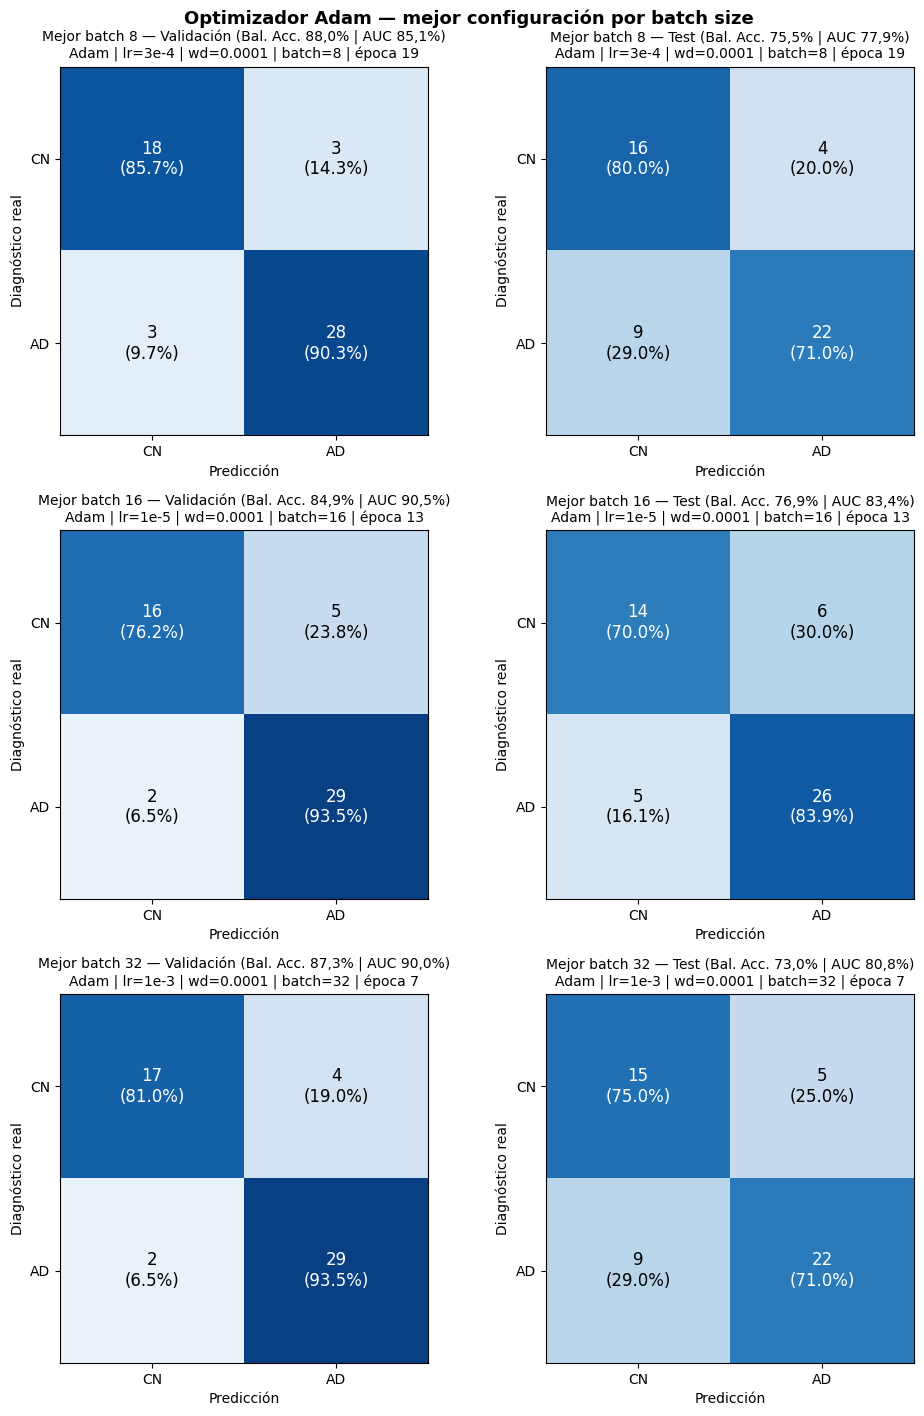

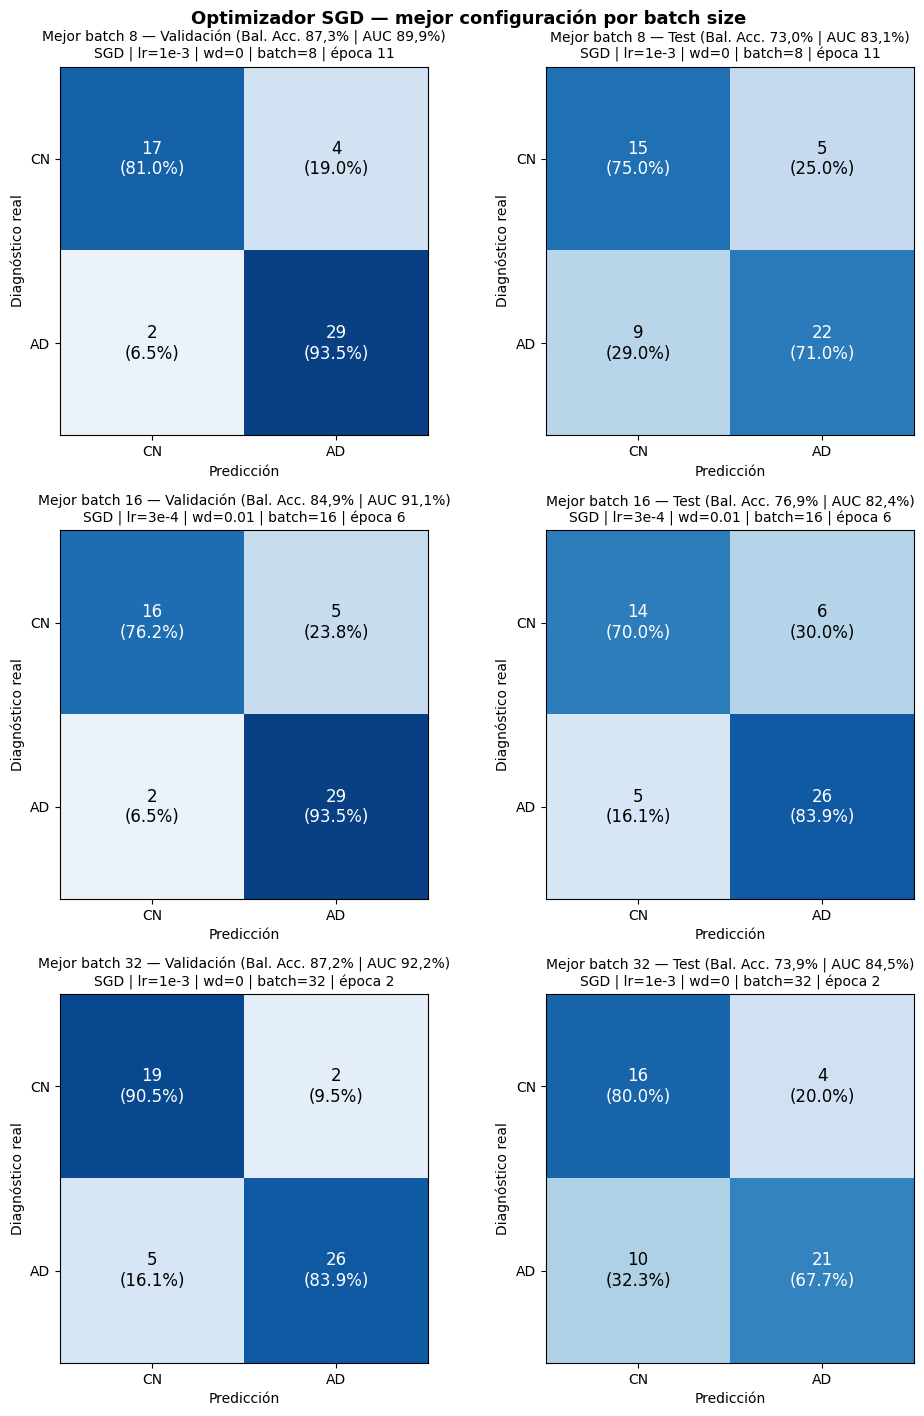

### Mejor configuración de cada optimizador

Optimizador,Batch,lr,wd,Mejor época,Bal. Acc. (val),AUC (val),F1 macro (val),Bal. Acc. (test),AUC (test),F1 macro (test),Empates
Adam,8,3e-4,0.0001,19,"88,0%","85,1%","88,0%","75,5%","77,9%","74,2%",—
SGD,8,1e-3,0,11,"87,3%","89,9%","87,8%","73,0%","83,1%","72,0%",—


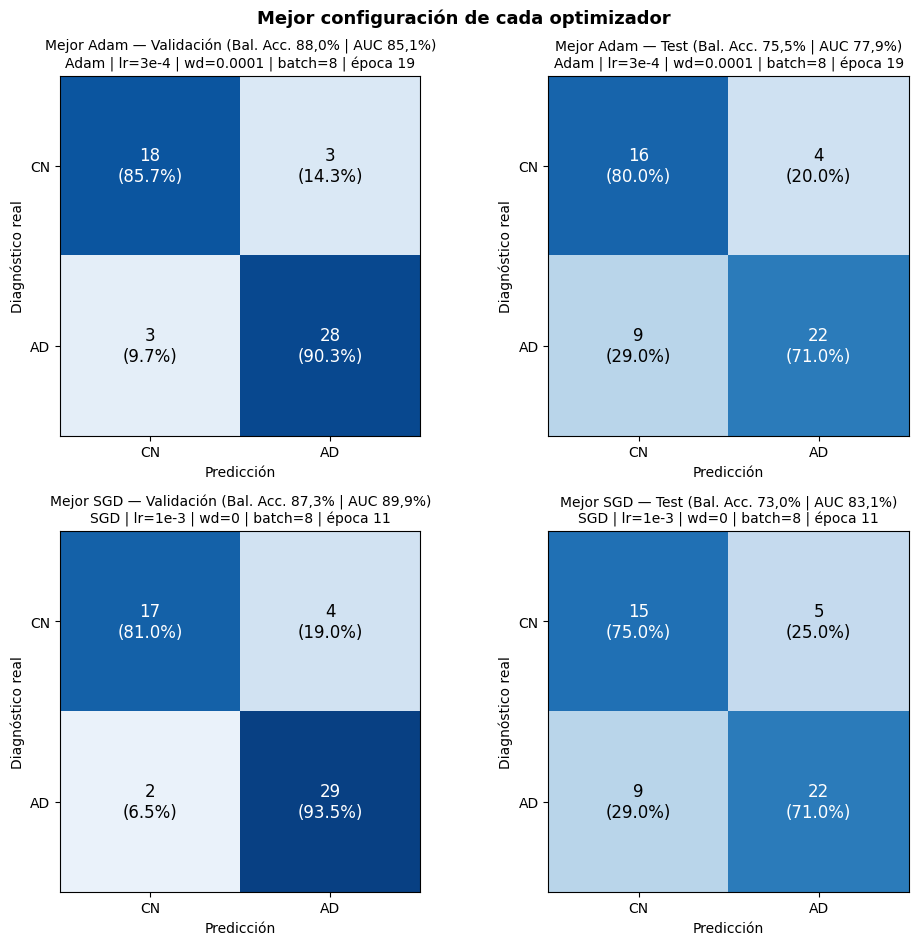

In [ ]:
SORT_COLS = ["valid_balanced_accuracy", "valid_auc"]


def pick_best(sub):
    """Mejor corrida por Bal. Acc. (val), desempate por AUC (val). Devuelve también los empates exactos."""
    sub = sub.sort_values(SORT_COLS, ascending=False, kind="mergesort")
    best = sub.iloc[0]
    ties = sub[np.isclose(sub["valid_balanced_accuracy"], best["valid_balanced_accuracy"]) &
               np.isclose(sub["valid_auc"], best["valid_auc"])].iloc[1:]
    empates = ", ".join("bs={} lr={} wd={}".format(int(t.batchsize), fmt_lr(t.learning_rate), fmt_wd(t.decay_rate))
                        for t in ties.itertuples())
    return best, empates


def summary_row(run, empates):
    return {"Optimizador": run["optimizer"], "Batch": int(run["batchsize"]),
            "lr": fmt_lr(run["learning_rate"]), "wd": fmt_wd(run["decay_rate"]),
            "Mejor época": fmt_int(run["best_epoch"]),
            "Bal. Acc. (val)": fmt_pct(run["valid_balanced_accuracy"]), "AUC (val)": fmt_pct(run["valid_auc"]),
            "F1 macro (val)": fmt_pct(run["valid_f1_macro"]),
            "Bal. Acc. (test)": fmt_pct(run["test_balanced_accuracy"]), "AUC (test)": fmt_pct(run["test_auc"]),
            "F1 macro (test)": fmt_pct(run["test_f1_macro"]),
            "Empates": empates or "—"}


def draw_run(axes_row, run, label):
    fig_dir = OUT_DIR / exp_name(run["optimizer"], run["learning_rate"], run["decay_rate"], run["batchsize"]) / "figures"
    desc = "{} | lr={} | wd={} | batch={} | época {}".format(
        run["optimizer"], fmt_lr(run["learning_rate"]), fmt_wd(run["decay_rate"]),
        int(run["batchsize"]), int(run["best_epoch"]))
    for c, split in enumerate(["valid", "test"]):
        p = pd.read_csv(fig_dir / "predictions_{}.csv".format(split))
        name = "Validación" if split == "valid" else "Test"
        draw_confusion(axes_row[c], p["y_true"], p["y_pred"],
                       "{} — {} (Bal. Acc. {} | AUC {})\n{}".format(
                           label, name, fmt_pct(run["{}_balanced_accuracy".format(split)]),
                           fmt_pct(run["{}_auc".format(split)]), desc))


# ---------------------------------------------------------------------
# 8.1  Mejor configuración por batch size de cada optimizador
# ---------------------------------------------------------------------
picks = {}   # (opt, bs) -> (run, empates)
for opt in OPTIMIZERS:
    for bs in BATCH_SIZES:
        sub = df[(df["optimizer"] == opt) & (df["batchsize"] == bs)]
        if not sub.empty:
            picks[(opt, bs)] = pick_best(sub)

display(Markdown("### Mejor configuración por batch size y optimizador"))
display(pd.DataFrame([summary_row(run, emp) for run, emp in picks.values()]).style.hide(axis="index"))

for opt in OPTIMIZERS:
    bss = [bs for bs in BATCH_SIZES if (opt, bs) in picks]
    if not bss:
        continue
    fig, axes = plt.subplots(len(bss), 2, figsize=(10, 4.8 * len(bss)), squeeze=False)
    for r, bs in enumerate(bss):
        run, _ = picks[(opt, bs)]
        draw_run(axes[r], run, "Mejor batch {}".format(bs))
    fig.suptitle("Optimizador {} — mejor configuración por batch size".format(opt), fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(BASE_DIR / "confusion_mejor_por_batch_{}.png".format(opt), dpi=DPI)
    plt.show()

# ---------------------------------------------------------------------
# 8.2  Mejor configuración de cada optimizador
# ---------------------------------------------------------------------
best_opt = {}
for opt in OPTIMIZERS:
    sub = df[df["optimizer"] == opt]
    if not sub.empty:
        best_opt[opt] = pick_best(sub)

display(Markdown("### Mejor configuración de cada optimizador"))
display(pd.DataFrame([summary_row(run, emp) for run, emp in best_opt.values()]).style.hide(axis="index"))

fig, axes = plt.subplots(len(best_opt), 2, figsize=(10, 4.8 * len(best_opt)), squeeze=False)
for r, (opt, (run, _)) in enumerate(best_opt.items()):
    draw_run(axes[r], run, "Mejor {}".format(opt))
fig.suptitle("Mejor configuración de cada optimizador", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(BASE_DIR / "confusion_mejor_por_optimizador.png", dpi=DPI)
plt.show()

## 9. Descargar resultados (opcional)

In [ ]:
zip_path = shutil.make_archive("/content/ftt_optimizadores_resultados", "zip", BASE_DIR)
files.download(zip_path)

## 10. Test ADNI (test externo)

Se entrena **solo con BrainLat** (master.csv ya cargado, mismas particiones y protocolo) con 3 configuraciones fijas, la época se elige con la validación de BrainLat y el modelo resultante se evalúa sobre **todo el CSV de ADNI** como test externo.

| Modelo | Optimizador | lr | wd | Batch |
|---|---|---|---|---|
| FT-Transformer | AdamW | 3e-5 | 0 | 32 |
| FT-Transformer | SGD | 1e-3 | 0.0001 | 8 |
| FT-Transformer | Adam | 3e-5 | 0.01 | 32 |

ADNI se preprocesa con las estadísticas de **train de BrainLat** (medianas, media, desviación y categorías de `sex`), sin reajustar nada con ADNI. En `DX`, AD puede venir como `Dementia` o `AD`; otros diagnósticos (p. ej. MCI) se excluyen. La columna `split` de ADNI, si existe, se ignora.

Requiere haber ejecutado las secciones 0–4 (instalación, configuración, CSV de BrainLat, datos y entrenamiento).

In [ ]:
# =====================================================================
# 10. Test ADNI: entrenamiento en BrainLat, evaluación externa en ADNI
# =====================================================================
ADNI_CONFIGS = [  # (optimizador, learning rate, weight decay, batch size)
    ("AdamW", 3e-5, 0.0,  32),
    ("SGD",   1e-3, 1e-4, 8),
    ("Adam",  3e-5, 0.01, 32),
]
ADNI_POSITIVE = ["Dementia", "AD"]  # valores de DX que cuentan como AD en ADNI
ADNI_NEGATIVE = ["CN"]
ADNI_DIR = BASE_DIR / "test_adni"
ADNI_DIR.mkdir(parents=True, exist_ok=True)

# ---------- 10.1 Seleccionar el CSV de ADNI ----------
print("Selecciona el CSV de ADNI")
adni_up = files.upload()
if not adni_up:
    raise ValueError("No se seleccionó ningún archivo de ADNI.")
adni_fname = next(iter(adni_up))
adni_raw = pd.read_csv(io.BytesIO(adni_up[adni_fname]))
print("Cargado '{}': {} filas x {} columnas".format(adni_fname, *adni_raw.shape))

# ---------- 10.2 Preprocesar ADNI con las estadísticas de train de BrainLat ----------
def _norm_cat(v):
    if isinstance(v, (int, float, np.integer, np.floating)) and float(v).is_integer():
        v = int(v)
    return str(v).strip().lower()

def brainlat_train_stats():
    """Mismas estadísticas que load_data() calcula sobre train de BrainLat."""
    df = raw_df.copy()
    df[SPLIT_COL] = df[SPLIT_COL].map(_norm_split)
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin([POSITIVE, NEGATIVE])]
    train = df[df[SPLIT_COL] == "train"]
    cont = info["cont_features"]
    tr = train[cont].apply(pd.to_numeric, errors="coerce")
    medians = tr.median()
    tr = tr.astype("float32").fillna(medians)
    return {"medians": medians, "mean": tr.mean(), "std": tr.std().replace(0, 1.0),
            "cats": {c: sorted(train[c].dropna().unique().tolist()) for c in CAT_FEATURES},
            "modes": {c: train[c].mode().iloc[0] for c in CAT_FEATURES}}

def load_adni(raw, st):
    df = raw.copy()
    cont = info["cont_features"]
    missing = [c for c in [LABEL_COL] + cont + CAT_FEATURES if c not in df.columns]
    if missing:
        raise ValueError("Faltan columnas en el CSV de ADNI: {}".format(missing))
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    keep = df[LABEL_COL].isin(ADNI_POSITIVE + ADNI_NEGATIVE)
    if (~keep).any():
        print("  [AVISO] Se excluyen {} filas con DX distinto de CN/AD: {}".format(
            int((~keep).sum()), df.loc[~keep, LABEL_COL].value_counts().to_dict()))
    df = df[keep].reset_index(drop=True)
    if df.empty:
        raise ValueError("ADNI no tiene sujetos CN/AD.")

    X = df[cont].apply(pd.to_numeric, errors="coerce")
    n_nan = X.isna().sum()
    if n_nan.any():
        print("  [AVISO] Faltantes en ADNI imputados con la mediana de train de BrainLat:",
              n_nan[n_nan > 0].to_dict())
    X = X.astype("float32").fillna(st["medians"])
    X = (X - st["mean"]) / st["std"]

    cat_codes = []
    for c in CAT_FEATURES:
        cats = st["cats"][c]
        mapping = {_norm_cat(v): i for i, v in enumerate(cats)}
        col = df[c].fillna(st["modes"][c]).map(_norm_cat)
        unseen = set(col.unique()) - set(mapping)
        if unseen:
            raise ValueError("'{}' en ADNI tiene valores {} que no existen en BrainLat {}. "
                             "Recodifícalos para que coincidan.".format(c, sorted(unseen), cats))
        cat_codes.append(col.map(mapping).astype("int64").values)

    y = df[LABEL_COL].isin(ADNI_POSITIVE).astype("float32").values
    n_ad = int(y.sum())
    print("  ADNI: {} sujetos (AD={}, CN={})".format(len(y), n_ad, len(y) - n_ad))
    if n_ad == 0 or n_ad == len(y):
        raise ValueError("ADNI no tiene las dos clases.")
    return {
        "ids": df[ID_COL].values if ID_COL in df.columns else np.arange(len(df)),
        "x_cont": torch.tensor(X.values),
        "x_cat": torch.tensor(np.stack(cat_codes, axis=1)) if cat_codes else None,
        "y": torch.tensor(y),
    }

adni = load_adni(adni_raw, brainlat_train_stats())

# ---------- 10.3 Entrenar en BrainLat y evaluar en ADNI ----------
def _pct(v):
    return "—" if pd.isna(v) else "{:.1f}%".format(v * 100).replace(".", ",")

def _lr(x):
    m, e = "{:.0e}".format(float(x)).split("e")
    return "{}e{}".format(m, int(e))

def _wd(x):
    return np.format_float_positional(float(x), trim="-")

adni_rows, adni_raw_rows = [], []
for opt, lr, wd, bs in ADNI_CONFIGS:
    print("\n===== ftt {} lr={} wd={} batch={} =====".format(opt, lr, wd, bs))
    t = time.time()
    model, history, best_epoch = train_one(opt, lr, wd, bs)  # train/valid de BrainLat

    exp_dir = ADNI_DIR / exp_name(opt, lr, wd, bs)
    fig_dir = exp_dir / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), exp_dir / "best_model.pt")
    history.to_csv(exp_dir / "history.csv", index=False)

    prob, _ = predict(model, adni)
    y_true = adni["y"].numpy().astype(int)
    y_pred = (prob >= 0.5).astype(int)
    m = summary_metrics(y_true, y_pred, prob)

    title = "ftt | {} | lr={} | wd={} | batch={}".format(opt, _lr(lr), _wd(wd), bs)
    plot_confusion(y_true, y_pred, fig_dir / "confusion_matrix_adni.png",
                   "Matriz de confusión — Test ADNI\n" + title)
    plot_roc(y_true, prob, fig_dir / "roc_adni.png", "Curva ROC — Test ADNI\n" + title)
    pd.DataFrame({ID_COL: adni["ids"], "y_true": y_true, "y_pred": y_pred, "prob_AD": prob}).to_csv(
        fig_dir / "predictions_adni.csv", index=False)
    print("  mejor época (val BrainLat) {} | Bal. Acc. ADNI {} | AUC ADNI {} | {:.0f} s".format(
        best_epoch, _pct(m["balanced_accuracy"]), _pct(m["auc"]), time.time() - t))

    adni_raw_rows.append({"modelo": "FT-Transformer", "optimizer": opt, "learning_rate": lr,
                          "decay_rate": wd, "batchsize": bs, "best_epoch": best_epoch, **m})
    adni_rows.append({
        "Modelo": "FT-Transformer", "Optimizador": opt, "lr": _lr(lr), "wd": _wd(wd), "Batch": bs,
        "Bal. Acc. (test)": _pct(m["balanced_accuracy"]),
        "Sens. AD (test)": _pct(m["sensitivity_AD"]),
        "Esp. CN (test)": _pct(m["specificity_CN"]),
        "AUC (test)": _pct(m["auc"]),
        "F1 macro (test)": _pct(m["f1_macro"]),
        "F1 pond. (test)": _pct(m["f1_weighted"]),
        "TP (test)": m["TP"], "FN (test)": m["FN"], "TN (test)": m["TN"], "FP (test)": m["FP"],
        "Acc. (test)": _pct(m["accuracy"]),
        "N muestras": m["n"],
    })

# ---------- 10.4 Tabla de resultados ----------
adni_table = pd.DataFrame(adni_rows)
display(Markdown("### Test ADNI (entrenado en BrainLat)"))
display(adni_table.style.hide(axis="index"))

adni_xlsx = ADNI_DIR / "resultados_test_adni.xlsx"
with pd.ExcelWriter(adni_xlsx, engine="openpyxl") as writer:
    adni_table.to_excel(writer, sheet_name="Test ADNI", index=False)
    pd.DataFrame(adni_raw_rows).to_excel(writer, sheet_name="Valores crudos", index=False)
pd.DataFrame(adni_raw_rows).to_csv(ADNI_DIR / "resultados_test_adni.csv", index=False)
print("Resultados guardados en", ADNI_DIR)


Selecciona el CSV de ADNI


Saving master.csv to master.csv
Cargado 'master.csv': 100 filas x 24 columnas
  ADNI: 100 sujetos (AD=50, CN=50)

===== ftt AdamW lr=3e-05 wd=0.0 batch=32 =====
  mejor época (val BrainLat) 8 | Bal. Acc. ADNI 88,0% | AUC ADNI 96,8% | 3 s

===== ftt SGD lr=0.001 wd=0.0001 batch=8 =====
  mejor época (val BrainLat) 1 | Bal. Acc. ADNI 88,0% | AUC ADNI 96,6% | 13 s

===== ftt Adam lr=3e-05 wd=0.01 batch=32 =====
  mejor época (val BrainLat) 8 | Bal. Acc. ADNI 88,0% | AUC ADNI 96,8% | 3 s


### Test ADNI (entrenado en BrainLat)

Modelo,Optimizador,lr,wd,Batch,Bal. Acc. (test),Sens. AD (test),Esp. CN (test),AUC (test),F1 macro (test),F1 pond. (test),TP (test),FN (test),TN (test),FP (test),Acc. (test),N muestras
FT-Transformer,AdamW,3e-5,0,32,"88,0%","96,0%","80,0%","96,8%","87,9%","87,9%",48,2,40,10,"88,0%",100
FT-Transformer,SGD,1e-3,0.0001,8,"88,0%","82,0%","94,0%","96,6%","88,0%","88,0%",41,9,47,3,"88,0%",100
FT-Transformer,Adam,3e-5,0.01,32,"88,0%","96,0%","80,0%","96,8%","87,9%","87,9%",48,2,40,10,"88,0%",100


Resultados guardados en /content/ftt_optimizadores/test_adni
